<a href="https://colab.research.google.com/github/nikepb01/ComputerVision_Colab/blob/main/12%EA%B0%95~13%EA%B0%95_%EC%8B%A4%EC%8A%B5(%EC%9D%B4%EB%AF%B8%EC%A7%80_%EB%A7%A4%EC%B9%AD%EA%B3%BC_%EC%B6%94%EC%A0%812).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **실습9_특징 매칭과 객체 추적**

## 01 특징 디스크립터

In [4]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [5]:
import cv2
print(cv2.__version__)

4.14.0


### **01.1 SIFT (Scale-Invariant Feature Transform)**

keypoint: 92
descriptor: (92, 128)
[[ 0.  0.  0. ...  0.  0.  2.]
 [ 1.  2.  0. ...  0.  0.  0.]
 [ 0. 98. 93. ...  0.  0.  0.]
 ...
 [26. 23.  0. ...  0.  0.  0.]
 [ 6. 10. 48. ...  0.  0.  0.]
 [10. 62. 82. ...  0.  0.  0.]]


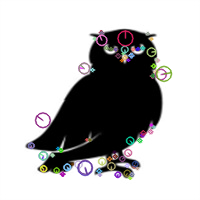

In [6]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread(
    '/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/owl_200x200.jpg')

if img is None:
    raise FileNotFoundError("이미지 파일을 찾을 수 없습니다.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# SIFT 생성 (수정된 부분)
sift = cv2.SIFT_create()

# 특징점과 디스크립터 추출
keypoints, descriptor = sift.detectAndCompute(gray, None)

print('keypoint:', len(keypoints))
print('descriptor:', descriptor.shape)
print(descriptor)

# 키 포인트 그리기
img_draw = cv2.drawKeypoints(img, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

cv2_imshow(img_draw)

### **01.2 SURF (Speeded Up Robust Features**

(207, 32)
[[182  64  98 ... 187 114 132]
 [  2  16  54 ...   4 161 131]
 [  2 141 134 ... 122 176 136]
 ...
 [ 74  56  82 ... 128   3  11]
 [106  56 114 ... 136  67   3]
 [ 98  32  68 ...   8 114 128]]


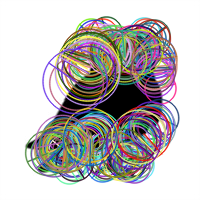

In [10]:
#SURF 특허 문제로 ORB로 대체 실
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

#img = cv2.imread("/content/drive/MyDrive/Colab Notebooks/photos/shapes/template/rabbitshape.jpg")
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/owl_200x200.jpg')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# ORB 생성
orb = cv2.ORB_create()

# 키 포인트 검출 및 서술자 계산 (surf 대신 orb 사용)
keypoints, descriptor = orb.detectAndCompute(gray, None)
print(descriptor.shape)
print(descriptor)

img_draw = cv2.drawKeypoints(img, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

cv2_imshow(img_draw)

### **01.3 ORB (Oriented FAST and Rotated BRIEF)**

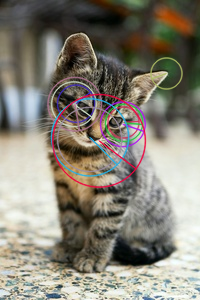

In [11]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

#img = cv2.imread("/content/drive/MyDrive/Colab Notebooks/photos/shapes/template/rabbitshape.jpg")
#img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/photos/building300x200.jpg')
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/고양이_200x300.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

orb = cv2.ORB_create(nfeatures=10)

keypoints, descriptor = orb.detectAndCompute(img, None)

img_draw = cv2.drawKeypoints(img, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

cv2_imshow(img_draw)

SURF 비활성화: OpenCV(4.14.0) /io/opencv_contrib/modules/xfeatures2d/src/surf.cpp:1026: error: (-213:The function/feature is not implemented) This algorithm is patented and is excluded in this configuration; Set OPENCV_ENABLE_NONFREE CMake option and rebuild the library in function 'create'

SIFT 특징점: 615


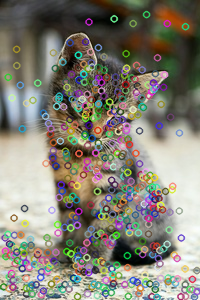

ORB 특징점: 447


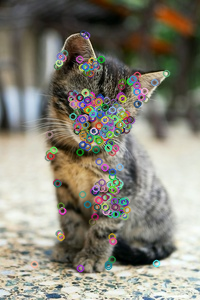

In [12]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# 이미지 불러오기
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/고양이_200x300.jpg')

if img is None:
    raise FileNotFoundError("이미지 경로를 확인하세요.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# SIFT, ORB 생성
sift = cv2.SIFT_create()
orb = cv2.ORB_create()

# SURF 지원 여부 확인
surf = None
if hasattr(cv2, "xfeatures2d") and hasattr(cv2.xfeatures2d, "SURF_create"):
    try:
        surf = cv2.xfeatures2d.SURF_create()
    except cv2.error as e:
        print("SURF 비활성화:", e)
else:
    print("SURF: 현재 OpenCV에서 지원되지 않습니다.")

# SIFT 특징점 검출
keypoints_sift, descriptors_sift = sift.detectAndCompute(gray, None)

# ORB 특징점 검출
keypoints_orb, descriptors_orb = orb.detectAndCompute(gray, None)

# SIFT 결과
print("SIFT 특징점:", len(keypoints_sift))
img_sift = cv2.drawKeypoints(img, keypoints_sift, None)
cv2_imshow(img_sift)

# SURF 결과 (지원되는 환경에서만 실행)
if surf is not None:
    keypoints_surf, descriptors_surf = surf.detectAndCompute(gray, None)
    print("SURF 특징점:", len(keypoints_surf))
    img_surf = cv2.drawKeypoints(img, keypoints_surf, None)
    cv2_imshow(img_surf)

# ORB 결과
print("ORB 특징점:", len(keypoints_orb))
img_orb = cv2.drawKeypoints(img, keypoints_orb, None)
cv2_imshow(img_orb)

## **02 특징 매칭(Feature Matching)**

### **02.1 BFMatcher(Brute-Force Matcher)**

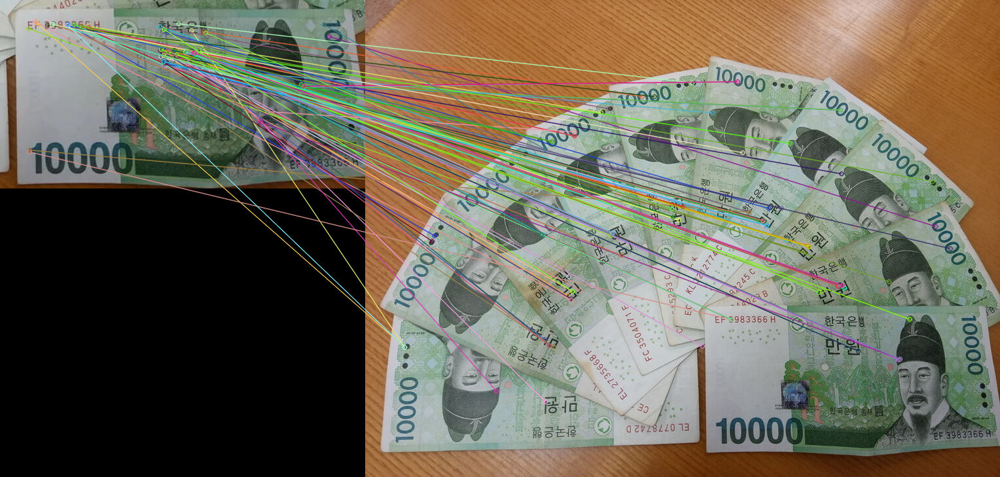

In [13]:
#BFMatcher.match()와 cv2.drawMatches()적용
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/money_1.jpg')
img2 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/money.jpg')
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)


#detector = cv2.xfeatures2d.SIFT_create()
#detector = cv2.xfeatures2d.SURF_create()
detector = cv2.ORB_create()

kp1, desc1 = detector.detectAndCompute(gray1, None)
kp2, desc2 = detector.detectAndCompute(gray2, None)

# BFMatcher 생성, L1 거리(SIFT, SURF)/Hamming 거리(ORB), 상호 체크
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

#최적의 매치 반환
matches = bf.match(desc1, desc2)

#매칭 결과를 거리가 가장 가까운 선부터 오름차순으로 정렬
matches = sorted(matches, key = lambda x:x.distance)

# 100개의 매칭 결과 그리기
result = cv2.drawMatches(img1, kp1, img2, kp2, matches[:100], None, flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)


cv2_imshow(result)

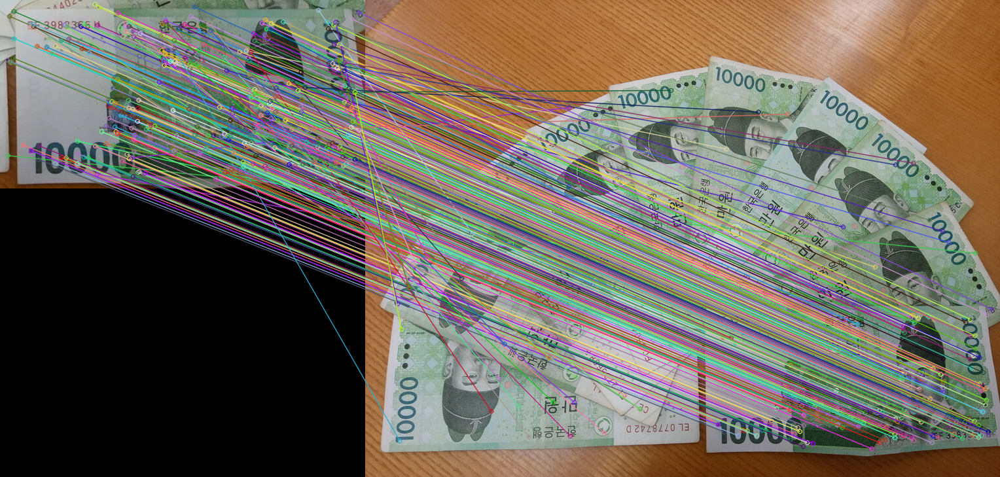

In [14]:
#BFMatcher.knnMatch()과 cv2.drawMatchesKnn 적용
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/money_1.jpg') # queryImage
img2 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/money.jpg') # trainImage
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()


kp1, des1 = sift.detectAndCompute(img1,None)
kp2, des2 = sift.detectAndCompute(img2,None)

# BFMatcher with default params
bf = cv2.BFMatcher()
matches = bf.knnMatch(des1,des2, k=2)

# 거리비율 테스트 적용
good = []
for m,n in matches:
    if m.distance < 0.75*n.distance:
        good.append([m])

# cv2.drawMatchesKnn expects list of lists as matches.
result = cv2.drawMatchesKnn(img1,kp1,img2,kp2,good,None,flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)

cv2_imshow(result)

### **02.2 FLANN based Matcher (Fast Library for Approximate Nearest Neighbors)**

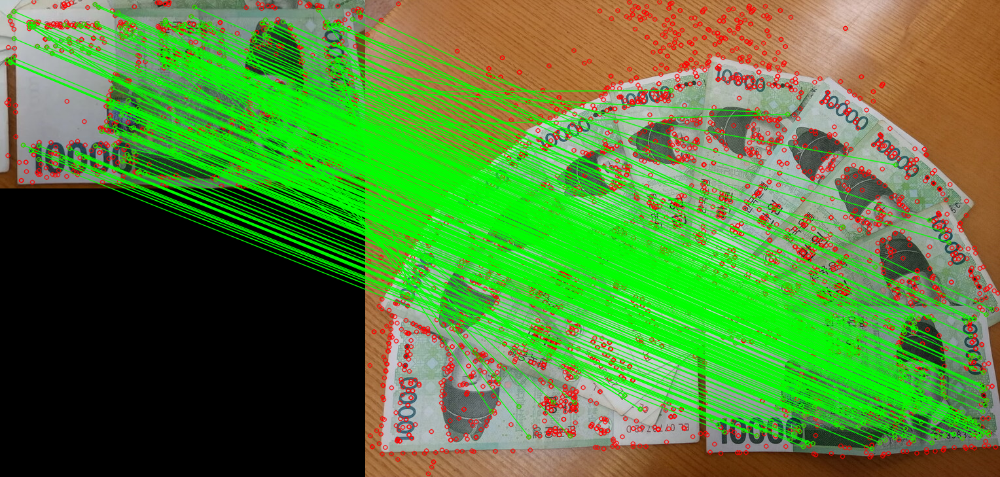

In [15]:
# FLANNMatcher와 SIFT로 매칭
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/money_1.jpg') # queryImage
img2 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/money.jpg') # trainImage

detector = cv2.SIFT_create()
#detector = cv2.xfeatures2d.SURF_create()

# 키 포인트와 디스크립터 추출
kp1, des1 = detector.detectAndCompute(img1,None)
kp2, des2 = detector.detectAndCompute(img2,None)

# 인덱스 파라미터와 검색 파라미터 설정
FLANN_INDEX_KDTREE = 1
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks=50)   # or pass empty dictionary

# Flann 매처 생성
flann = cv2.FlannBasedMatcher(index_params, search_params)
# 매칭 계산
matches = flann.knnMatch(des1,des2,k=2)

# Need to draw only good matches, so create a mask
matchesMask = [[0,0] for i in range(len(matches))]

# ratio test as per Lowe's paper
for i,(m,n) in enumerate(matches):
    if m.distance < 0.7*n.distance:
        matchesMask[i]=[1,0]

draw_params = dict(matchColor = (0,255,0),
                   singlePointColor = (0,0,255),
                   matchesMask = matchesMask,
                   flags = 0)

# 매칭 그리기
result = img3 = cv2.drawMatchesKnn(img1,kp1,img2,kp2,matches, None,**draw_params)

cv2_imshow(result)

### **02.3 호모그래피(Homography)와 원근변환 활용**

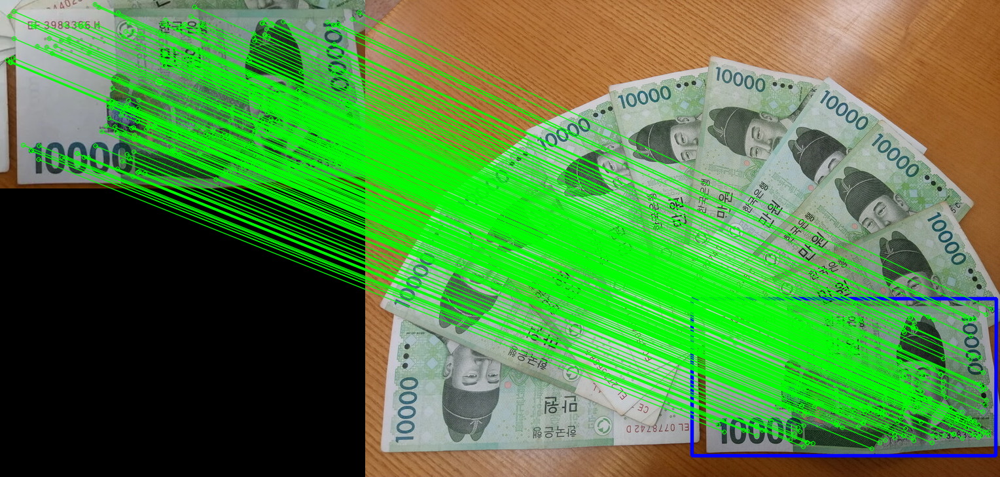

In [16]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


MIN_MATCH_COUNT = 10

img1 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/money_1.jpg')
img2 = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/money.jpg')



sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(img1,None)
kp2, des2 = sift.detectAndCompute(img2,None)

FLANN_INDEX_KDTREE = 0
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks = 50)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1,des2,k=2)

# store all the good matches as per Lowe's ratio test.
good = []
for m,n in matches:
  if m.distance < 0.7*n.distance:
    good.append(m)

if len(good)>MIN_MATCH_COUNT:
  src_pts = np.float32([ kp1[m.queryIdx].pt for m in good ]).reshape(-1,1,2)
  dst_pts = np.float32([ kp2[m.trainIdx].pt for m in good ]).reshape(-1,1,2)

  M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC,5.0)
  matchesMask = mask.ravel().tolist()


  h,w,d = img1.shape
  pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1,1,2)
  dst = cv2.perspectiveTransform(pts,M)

  img2 = cv2.polylines(img2,[np.int32(dst)],True,255,3, cv2.LINE_AA)

else:
  print("Not enough matches are found - %d/%d" % (len(good),MIN_MATCH_COUNT))
  matchesMask = None

draw_params = dict(matchColor = (0,255,0), # draw matches in green color
                   singlePointColor = None,
                   matchesMask = matchesMask, # draw only inliers
                   flags = 2)

result = cv2.drawMatches(img1,kp1,img2,kp2,good,None,**draw_params)
cv2_imshow(result)

## **03 이미지 스티칭 (Image Stitching)**

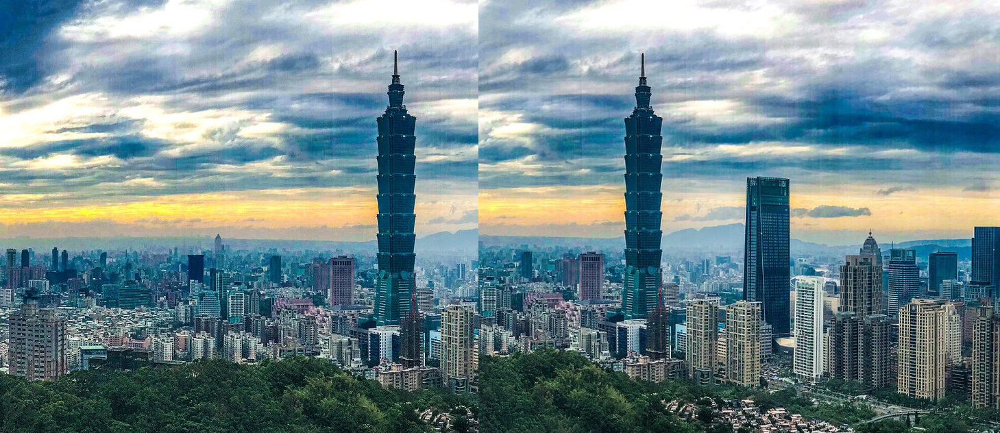

In [17]:
from random import randrange
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

rgb_l = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/tower12.jpg')
rgb_r = cv2.imread('/content/drive/MyDrive/Colab Notebooks/AI영상데이터처리/images/12강/tower13.jpg')

gray_l = cv2.cvtColor(rgb_l, cv2.COLOR_RGB2GRAY)
gray_r = cv2.cvtColor(rgb_r, cv2.COLOR_RGB2GRAY)

shift_frame = cv2.hconcat([rgb_l,rgb_r])
cv2_imshow(shift_frame)

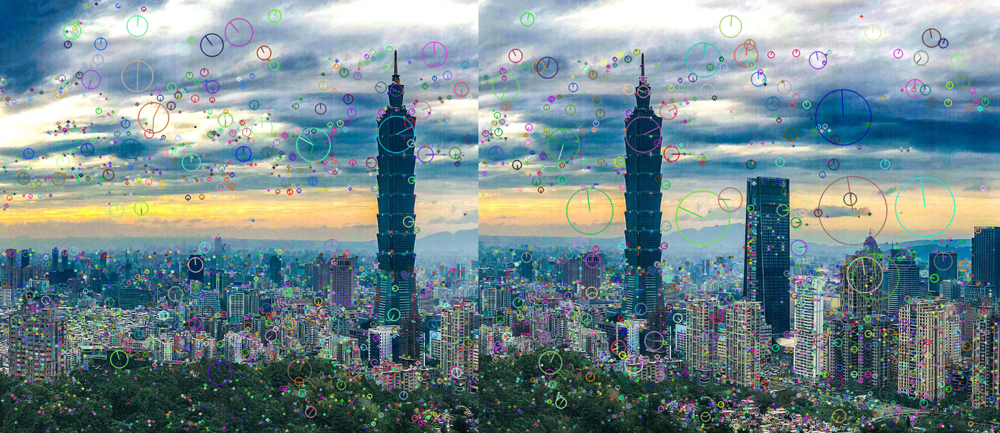

In [18]:
#SIFT를 사용해 키포인트와 디스크립터 추출
feature_extractor = cv2.SIFT_create()

kp_l, desc_l = feature_extractor.detectAndCompute(gray_l, None)
kp_r, desc_r = feature_extractor.detectAndCompute(gray_r, None)

test_l = cv2.drawKeypoints(rgb_l, kp_l, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
test_r = cv2.drawKeypoints(rgb_r, kp_r, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

shift_frame = cv2.hconcat([test_l, test_r])
cv2_imshow(shift_frame)

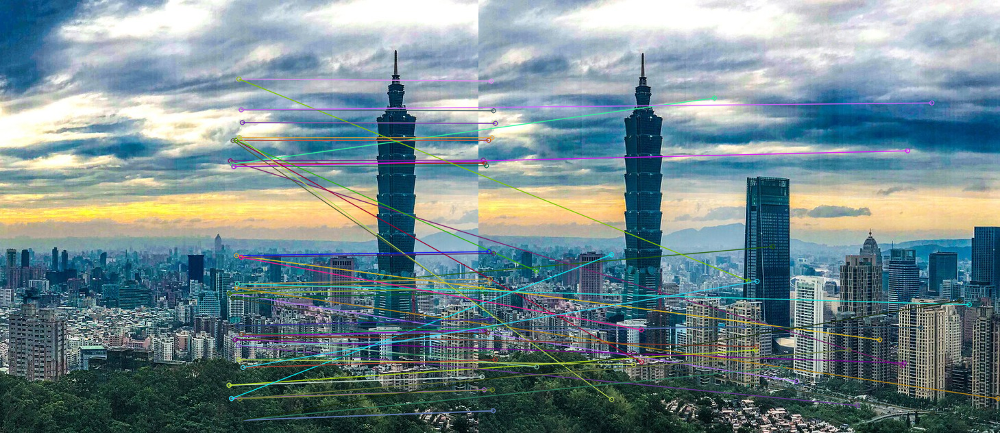

In [19]:
#BFMatcher()를 사용해 필요한 특징점만 추출
bf = cv2.BFMatcher()
matches = bf.knnMatch(desc_l, desc_r, k=2)

# Apply ratio test
good_match = []
for m in matches:
    if m[0].distance/m[1].distance < 0.5:
        good_match.append(m)
good_match_arr = np.asarray(good_match)

# 30 개의 매칭점만 추출
im_matches = cv2.drawMatchesKnn(rgb_l, kp_l, rgb_r, kp_r,
                                good_match[0:30], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)


cv2_imshow(im_matches)

In [20]:
#이미지간의 호모그래피 찾기
good_kp_l = np.array([kp_l[m.queryIdx].pt for m in good_match_arr[:, 0]]).reshape(-1, 1, 2)
good_kp_r = np.array([kp_r[m.trainIdx].pt for m in good_match_arr[:, 0]]).reshape(-1, 1, 2)
homography, masked = cv2.findHomography(good_kp_r, good_kp_l, cv2.RANSAC, 5.0)

print(homography)

[[ 1.03535628e+00  5.45316958e-05  3.29011351e+02]
 [-1.07765025e-04  1.03484307e+00 -6.97564858e+00]
 [-2.28858259e-07  1.26517858e-07  1.00000000e+00]]


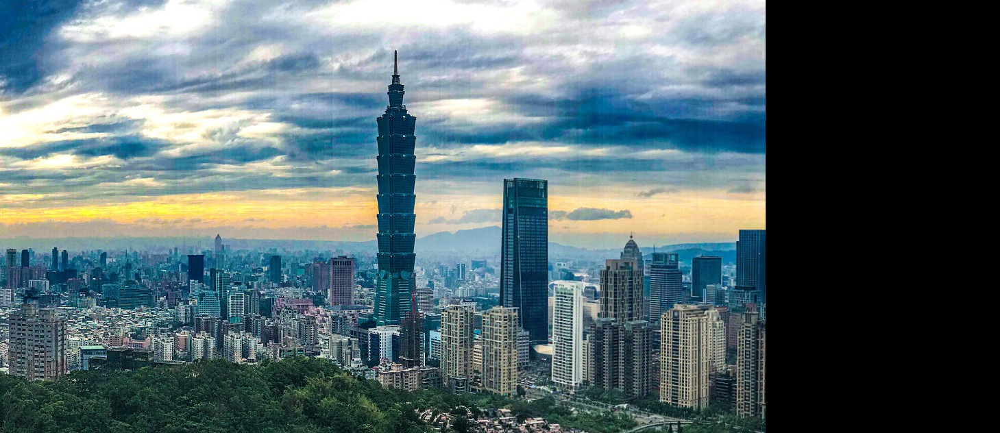

In [21]:
#원근 변환을 이용해 이미지 포개기
rgb_r_warped = cv2.warpPerspective(rgb_r, homography, (rgb_l.shape[1] + rgb_r.shape[1], rgb_l.shape[0]))
rgb_r_warped[0:rgb_l.shape[0], 0:rgb_l.shape[1]] = rgb_l

cv2_imshow(rgb_r_warped)

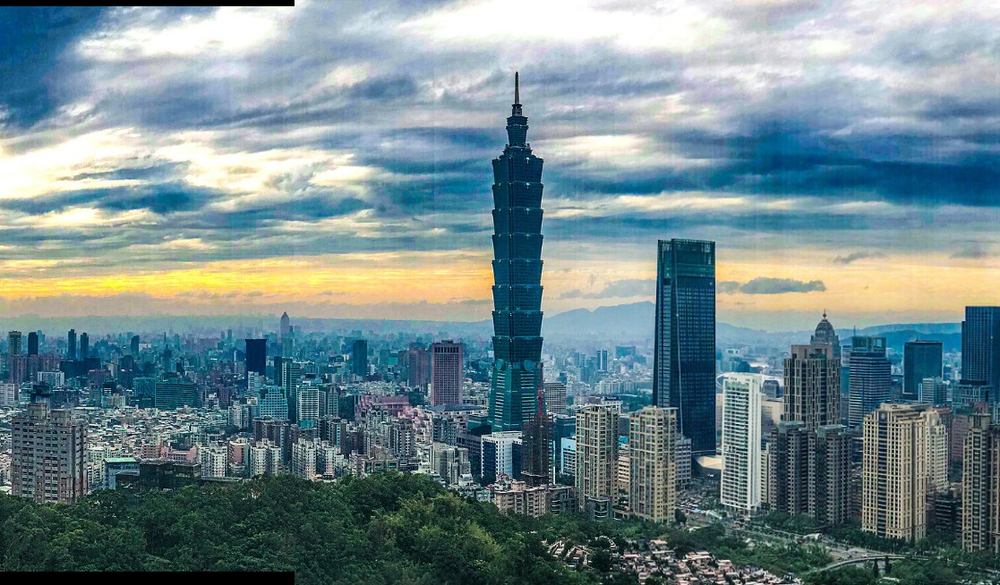

In [22]:
def warpTwoImages(img1, img2, H):
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    pts1 = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)
    pts2 = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)
    pts2_ = cv2.perspectiveTransform(pts2, H)
    pts = np.concatenate((pts1, pts2_), axis=0)
    [xmin, ymin] = np.int32(pts.min(axis=0).ravel() - 0.5)
    [xmax, ymax] = np.int32(pts.max(axis=0).ravel() + 0.5)
    t = [-xmin, -ymin]
    Ht = np.array([[1, 0, t[0]], [0, 1, t[1]], [0, 0, 1]])  # translate

    result = cv2.warpPerspective(img2, Ht@H, (xmax-xmin, ymax-ymin))
    result[t[1]:h1+t[1], t[0]:w1+t[0]] = img1
    return result


result = warpTwoImages(rgb_l, rgb_r, homography)
cv2_imshow(result)